In [1]:
!pip install cartopy

In [2]:
!pip uninstall -y shapely

Found existing installation: shapely 2.1.1
Uninstalling shapely-2.1.1:
  Successfully uninstalled shapely-2.1.1


In [4]:
!pip install shapely

  Using cached shapely-2.1.1-cp310-cp310-macosx_11_0_arm64.whl.metadata (6.8 kB)
Using cached shapely-2.1.1-cp310-cp310-macosx_11_0_arm64.whl (1.6 MB)


In [5]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [6]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

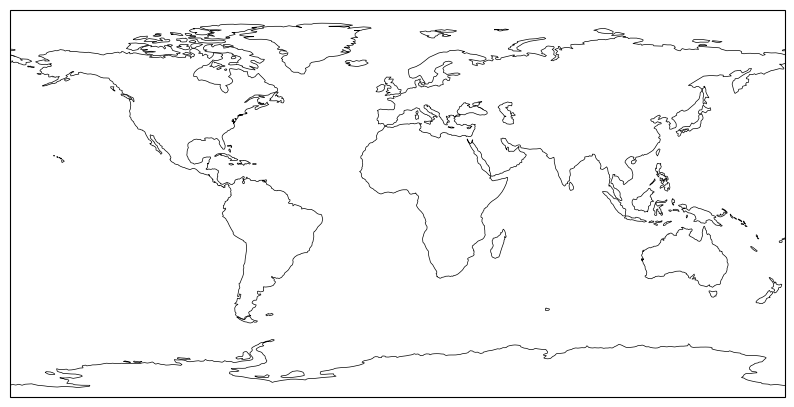

In [28]:
fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(resolution='110m', color='black', linewidth=0.5)

In [29]:
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                    linewidth=2, color='gray', alpha=0.5, linestyle='--')
gl.xlabels_top = False
gl.ylabels_right = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

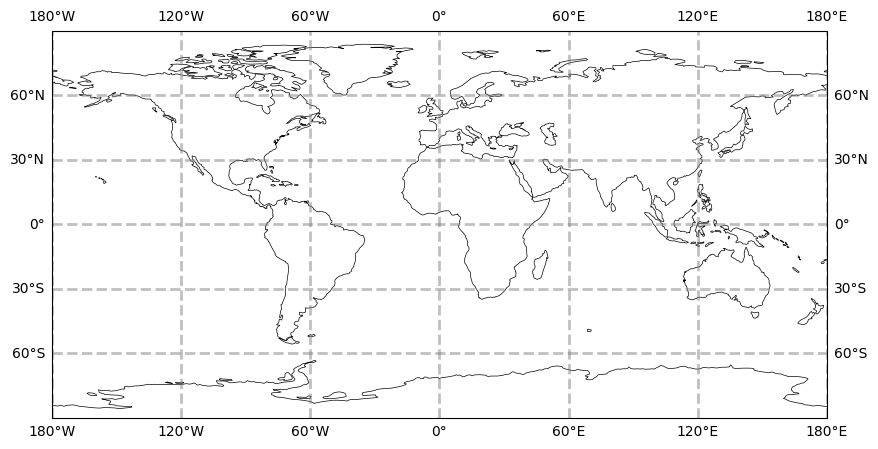

In [30]:
fig

In [31]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

ds = xr.open_dataset("./data/ice_conc_nh_ease2-250_cdr-v3p0-amsr_200206011200.nc")
ds

<xarray.Dataset> Size: 10MB
Dimensions:                         (time: 1, nv: 2, xc: 432, yc: 432)
Coordinates:
  * time                            (time) datetime64[ns] 8B 2002-06-01T12:00:00
  * xc                              (xc) float64 3kB -5.388e+03 ... 5.388e+03
  * yc                              (yc) float64 3kB 5.388e+03 ... -5.388e+03
    lat                             (yc, xc) float32 746kB ...
    lon                             (yc, xc) float32 746kB ...
Dimensions without coordinates: nv
Data variables:
    Lambert_Azimuthal_Grid          int32 4B ...
    time_bnds                       (time, nv) datetime64[ns] 16B ...
    ice_conc                        (time, yc, xc) float64 1MB ...
    raw_ice_conc_values             (time, yc, xc) float64 1MB ...
    total_standard_uncertainty      (time, yc, xc) float64 1MB ...
    smearing_standard_uncertainty   (time, yc, xc) float64 1MB ...
    algorithm_standard_uncertainty  (time, yc, xc) float64 1MB ...
    status_flag                     (time, yc, xc) float32 746kB ...
Attributes: (12/43)
    title:                     Sea Ice Concentration Climate Data Record Vers...
    summary:                   This climate data record of sea ice concentrat...
    topiccategory:             Oceans ClimatologyMeteorologyAtmosphere
    geospatial_lat_min:        16.62393
    geospatial_lat_max:        90.0
    geospatial_lon_min:        -180.0
    ...                        ...
    algorithm:                 SICCI3LF (19V, 37V, 37H)
    references:                Product User Manual v3 (2022),Algorithm Theore...
    product_id:                osi-458
    contributor_name:          Thomas Lavergne,Atle Soerensen,Rasmus Tonboe,C...
    contributor_role:          PrincipalInvestigator,author,author,author,aut...
    product_status:            released

In [32]:
ice_conc = ds['ice_conc'].isel(time=0)
ice_conc

<xarray.DataArray 'ice_conc' (yc: 432, xc: 432)> Size: 1MB
[186624 values with dtype=float64]
Coordinates:
    time     datetime64[ns] 8B 2002-06-01T12:00:00
  * xc       (xc) float64 3kB -5.388e+03 -5.362e+03 ... 5.362e+03 5.388e+03
  * yc       (yc) float64 3kB 5.388e+03 5.362e+03 ... -5.362e+03 -5.388e+03
    lat      (yc, xc) float32 746kB ...
    lon      (yc, xc) float32 746kB ...
Attributes:
    long_name:            fully filtered concentration of sea ice using atmos...
    standard_name:        sea_ice_area_fraction
    units:                %
    valid_min:            0
    valid_max:            10000
    grid_mapping:         Lambert_Azimuthal_Grid
    ancillary_variables:  total_standard_uncertainty status_flag
    comment:              this field is the primary sea ice concentration est...

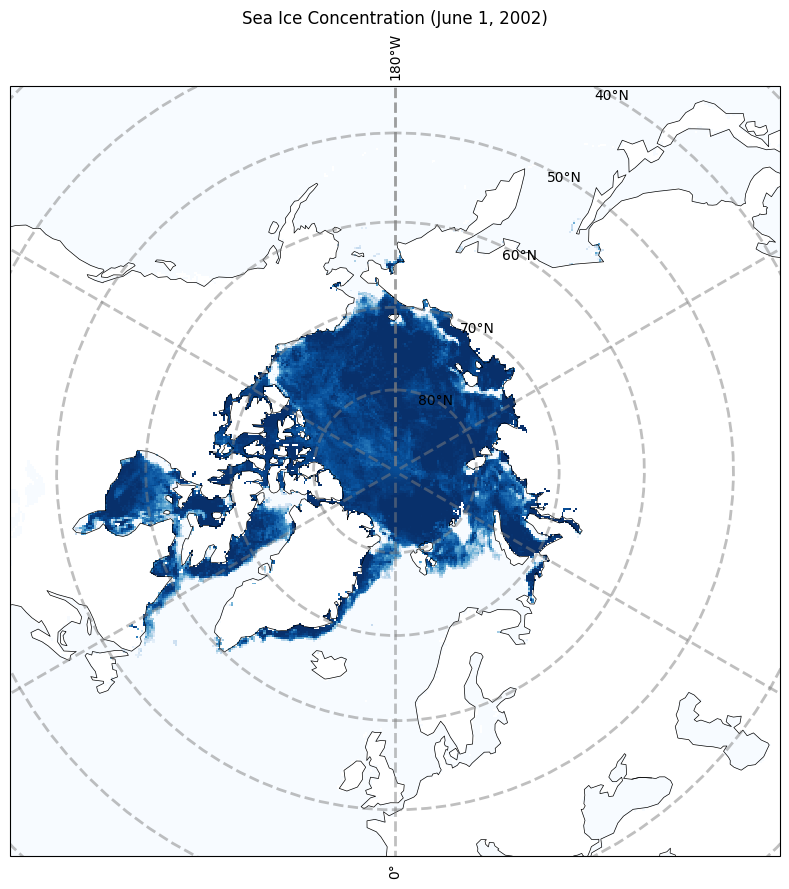

In [35]:
# Plotting the ice concentration data on cartopy 
import cartopy.crs as ccrs

fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.coastlines(resolution='110m', color='black', linewidth=0.5)
ax.set_extent([-180,180, 45, 90], crs=ccrs.PlateCarree())
ax.pcolormesh(ice_conc.lon, ice_conc.lat, ice_conc,
               transform=ccrs.PlateCarree(), cmap='Blues', vmin=0, vmax=100)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                    linewidth=2, color='gray', alpha=0.5, linestyle='--')
gl.xlabels_top = False
gl.ylabels_right = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
plt.title('Sea Ice Concentration (June 1, 2002)')
plt.show()